# 01 · Can we trust the data?

Before analysing anything, I want to be sure of four things, because every result later
depends on them:

1. The files I'm using are exactly the ones in the `data.zip` we were given.
2. Every value reads correctly: dates as dates, amounts as numbers, nothing lost on the way in.
3. Every record points to something real. A quote belongs to a real customer of the same
   business, a job to a real property, and so on.
4. My counts of quotes match the counts the platform keeps separately.

The checks live in one place (`quote_followup.audit`), so this notebook, the command line
(`quote-followup audit --zip ../data.zip`) and the automated tests all run the same code.

In [1]:
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "scripts"))

from quote_followup import audit
from quote_followup.config import load_settings
from quote_followup.data import load_quotes, read_table

pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 100)
settings = load_settings(ROOT / "config.toml")
DATA, ZIP, DICTIONARY = settings.data_dir, ROOT.parent / "data.zip", ROOT / "reference" / "DATA_DICTIONARY.csv"

## How the tables connect

This is the diagram that came with the data. Each business (SP) has its own customers, and
everything below them (properties, quotes, jobs, visits, invoices, payments) belongs to that
same business. When I check a link, I check it within the business, so a quote attached to
another business's customer counts as broken.

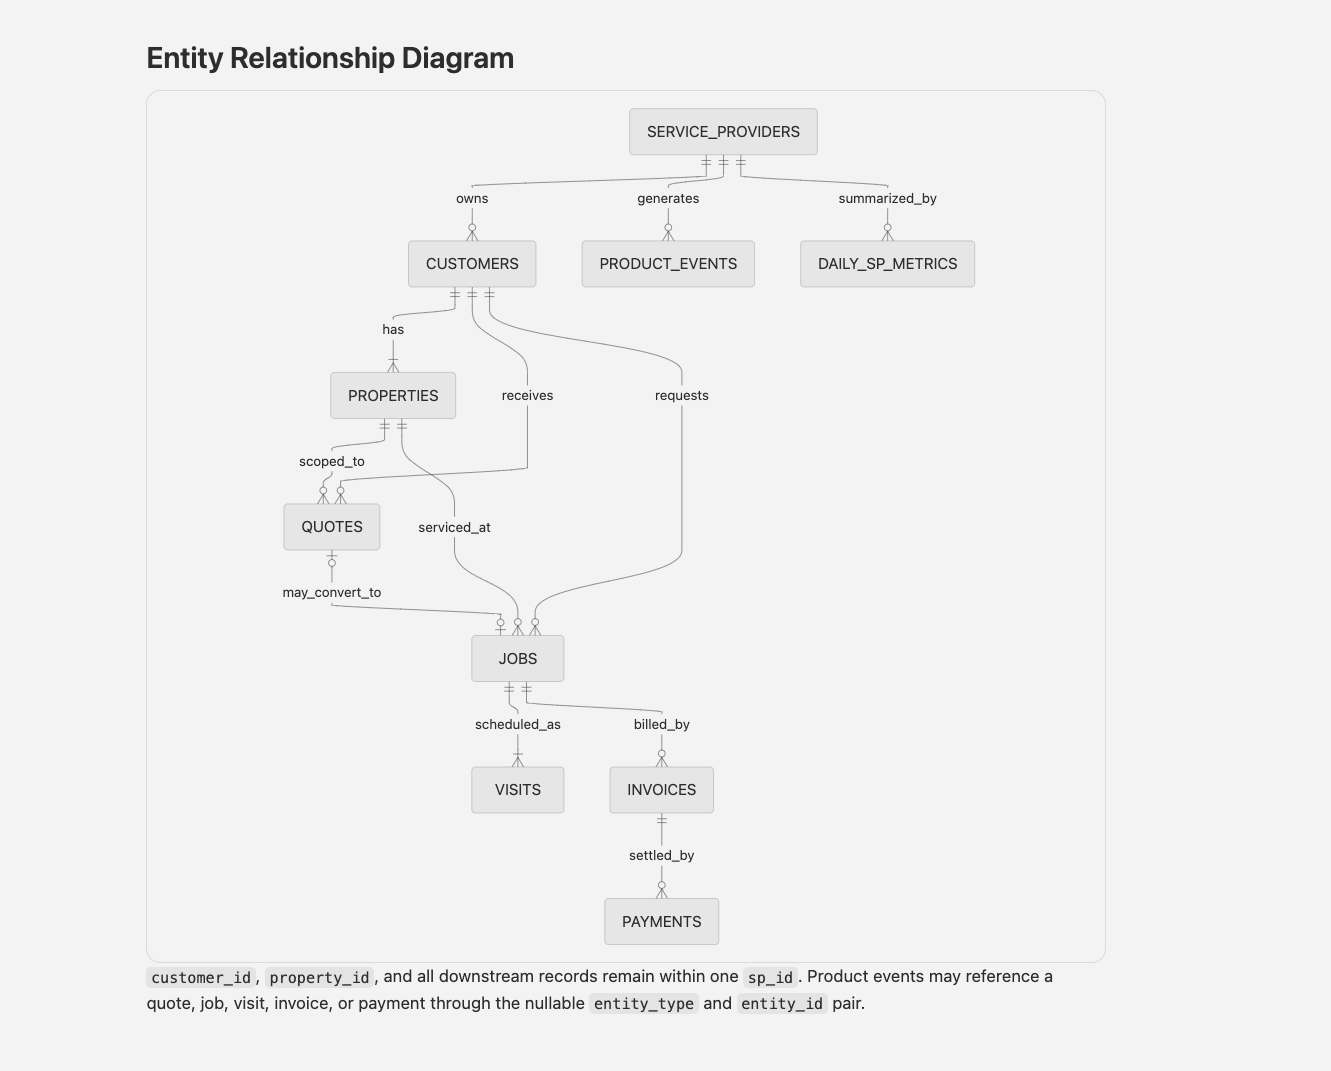

In [2]:
display(Image(ROOT / "reference" / "ERD.png", width=640))

## Running every check

One row per check. `ok` is True when it passes.

In [3]:
quotes = load_quotes(DATA)
report = audit.run(DATA, DICTIONARY, quotes, ZIP if ZIP.exists() else None)
summary = report.groupby("check", sort=False)["ok"].agg(checks="size", passed="sum")
display(summary)
print(f"{report['ok'].sum()} of {len(report)} checks pass")

,checks,passed
check,,
row count,10,10
columns,10,10
types parse,10,10
required present,10,10
key unique,10,10
links,16,16
quote rule,6,6
reconciles,4,4


76 of 76 checks pass


Every check passes. The two groups worth reading in full are the links between tables and the
cross-checks against the platform's own counts.

In [4]:
display(report[report["check"].isin(["links", "reconciles"])].reset_index(drop=True))

,check,table,detail,ok
0,links,customers,sp_id -> service_providers: 0 orphans,True
1,links,properties,customer_id+sp_id -> customers: 0 orphans,True
2,links,quotes,customer_id+sp_id -> customers: 0 orphans,True
3,links,quotes,property_id+customer_id+sp_id -> properties: 0 orphans,True
4,links,jobs,property_id+customer_id+sp_id -> properties: 0 orphans,True
5,links,jobs,quote_id+customer_id+sp_id -> quotes: 0 orphans,True
6,links,visits,job_id+customer_id+property_id+sp_id -> jobs: 0 orphans,True
7,links,invoices,job_id+customer_id+property_id+sp_id -> jobs: 0 orphans,True
8,links,payments,invoice_id+customer_id+sp_id -> invoices: 0 orphans,True
9,links,product_events,sp_id -> service_providers: 0 orphans,True


The cross-checks are the strongest evidence that I'm reading the quotes correctly.
`daily_sp_metrics` is a separate summary the platform keeps: how many quotes each business
created, sent and had accepted, day by day. Counting the same things myself from the quotes
table gives exactly the same numbers on every single business-day. It also confirms what the
`decided_at` column means, because the platform counts an acceptance on that date. On top of
that, every quote has its own "quote created" event in the product log, with the same timestamp.

## How the model reads quotes

The loader reads every column as plain text first, then converts dates using the exact format
in the files (like `2024-05-15T10:20:00`), and stops if anything doesn't fit. The usual
shortcut in pandas would silently leave a bad date as text, and nothing would complain.

In [5]:
print(quotes.dtypes.to_string())
display(quotes.head(3).T)

quote_id                        str
sp_id                           str
customer_id                     str
property_id                     str
workflow_type                   str
created_at           datetime64[us]
sent_at              datetime64[us]
expires_at           datetime64[us]
decided_at           datetime64[us]
status                          str
quoted_amount_usd           float64
line_item_count               int64
decline_reason                  str
customer_type                   str
customer_channel                str
business_name                   str
industry                        str
won                         float64
hours_to_send               float64
log_hours_to_send           float64
send_speed                      str
resolved_at          datetime64[us]
days_to_decision            float64


,0,1,2
quote_id,QU020966,QU009646,QU009494
sp_id,SP0418,SP0198,SP0196
customer_id,CU009997,CU004785,CU004725
property_id,PR009997,PR004785,PR004725
workflow_type,recurring,emergency,recurring
created_at,2024-01-01 08:06:00,2024-01-01 10:15:00,2024-01-01 10:16:00
sent_at,2024-01-01 09:06:00,2024-01-01 12:15:00,2024-01-01 14:16:00
expires_at,2024-01-31 09:06:00,2024-01-31 12:15:00,2024-01-31 14:16:00
decided_at,2024-01-12 16:06:00,2024-01-03 16:15:00,2024-01-04 21:16:00
status,declined,accepted,accepted


A few columns are worked out from the quote itself:

| column | what it means |
|---|---|
| `won` | 1 if accepted, 0 if declined or expired, blank for the 1,444 still marked "open" |
| `hours_to_send` | hours between writing the quote and sending it |
| `send_speed` | "within a day" or "after a day" |
| `resolved_at` | when the ending became known: the reply date, or the expiry date if nobody replied |
| `days_to_decision` | days between sending and the reply; blank if the quote expired |

## Four facts that shape the rest of the work

In [6]:
raw = audit.read_raw(DATA)
latest = {f"{t}.{c}": pd.to_datetime(raw[t][c]).max()
          for t in audit.TABLES for c in raw[t].columns if c.endswith("_at") or c == "reporting_date"}
latest = pd.Series(latest).sort_values(ascending=False)
display(latest.head(5).to_frame("latest date in the column"))

open_quotes = quotes[quotes["status"] == "open"]
print(f"quotes still marked open: {len(open_quotes):,}")
print(f"latest expiry date of any quote: {quotes['expires_at'].max():%d %b %Y}")
print(f"open quotes already past their expiry by 19 Mar 2025: {(open_quotes['expires_at'] < '2025-03-19').mean():.0%}")

,latest date in the column
visits.scheduled_start_at,2025-05-26 13:02:00
product_events.event_at,2025-03-19 11:24:00
payments.paid_at,2025-03-19 11:24:00
jobs.scheduled_start_at,2025-02-15 08:19:00
invoices.due_at,2025-02-11 17:04:00


quotes still marked open: 1,444
latest expiry date of any quote: 23 Jan 2025
open quotes already past their expiry by 19 Mar 2025: 100%


**1. The "open" quotes aren't really open.** The data was pulled on or after 19 Mar 2025
(payments and product events run up to that day). Every quote had expired by 23 Jan 2025. So
the 1,444 quotes still marked "open" aren't waiting for an answer; they look like a glitch in
the export. I leave them out, and notebook 05 shows that counting them as lost changes nothing.

In [7]:
late = quotes["days_to_decision"] > 45
print(f"replies that came more than 45 days after sending: {late.sum()} of {quotes['decided_at'].notna().sum():,}")

jobs = read_table(DATA / "jobs.csv", ["job_id", "quote_id", "planned_revenue_usd"], numbers={"planned_revenue_usd": float})
invoices = read_table(DATA / "invoices.csv", ["job_id", "status", "invoice_amount_usd"], numbers={"invoice_amount_usd": float})
invoiced = invoices[invoices["status"] != "void"].groupby("job_id")["invoice_amount_usd"].sum()
won = quotes.merge(jobs, on="quote_id").join(invoiced.rename("invoiced"), on="job_id")
value = won.assign(planned_vs_quote=won["planned_revenue_usd"] / won["quoted_amount_usd"],
                   invoiced_vs_quote=won["invoiced"] / won["quoted_amount_usd"])
display(value.groupby("workflow_type")[["planned_vs_quote", "invoiced_vs_quote"]].median().round(3))

replies that came more than 45 days after sending: 6 of 19,493


,planned_vs_quote,invoiced_vs_quote
workflow_type,,
emergency,1.025,1.022
project,1.025,1.024
recurring,1.024,1.023


**2. Waiting 45 days before learning from a quote loses almost nothing.** Only a handful of
replies ever came later than that.

**3. The quoted amount is a fair measure of what a win is worth.** For every type of work,
recurring included, the job that follows a won quote is planned and invoiced at within a few
percent of the quote. So "worth today" can use the quote amount.

**4. Customers who say no don't all behave alike.** Notebook 03 covers this one.